# M10-1 | 把 VPU 的硬體約束寫成 Quantizer：`MyVPUQuantizer`

M03 的 Quantizer 都是教材用的規則；真正的後端 Quantizer，是把硬體約束翻譯成標籤。這一章虛構一顆 VPU，約束與實作都在同目錄的 [`vpu_quantizer.py`](vpu_quantizer.py)（本專案的後端本體，不是 torchao 的 API），建議和這本 notebook 對照著讀。

- **A.** 八條約束各用 PT2E 的哪個機制實作、寫在 `vpu_quantizer.py` 的哪裡。
- **B.** scale 必須是 2 的冪次：自訂 observer 怎麼改 scale、付出什麼。
- **C.** `validate()`：動態 batch 的圖在 `prepare_pt2e` 裡就被擋下。
- **D.** VPU 上的 TinyConvNet：哪些 tensor 被迫用同一個 scale。
- **E.** `convert_pt2e` 之後：確認 Q/DQ 圖上的數字。

In [1]:
import torch

from common.pt2e import MinMaxObserver, convert_pt2e, export_module, get_xnnpack_quantizer, prepare_pt2e, quiet
from common.data import calibration_batches, make_tensors, trained_tiny_net
from common.graph_utils import observer_nodes, qdq_nodes, short, sqnr
from common.models import example_inputs
from common.viz import draw, table
from vpu_quantizer import VPU_OPS, MyVPUQuantizer, Pow2MinMaxObserver

quiet()
_ = torch.manual_seed(0)
BATCH = 16

`vpu_quantizer.py` 和這本 notebook 在同一個資料夾，所以可以直接 `from vpu_quantizer import …`。

## A. 八條約束 → PT2E 的機制 → 程式位置

VPU 是虛構的，但每條約束都是 VPU／NPU 類硬體常見的要求（一般說法，本專案沒有實機）：

| VPU 約束 | PT2E 做法 | `vpu_quantizer.py` 裡的位置 |
|---|---|---|
| (1) 只有 `VPU_OPS` 有 kernel | 其餘 op 不貼標籤 → 留在 fp32（M03-6） | `VPU_OPS`、`annotate()` 的最後 |
| (2) activation per-tensor symmetric | `QuantizationSpec(qscheme=per_tensor_symmetric)` | `act_spec()` |
| (3) weight per-channel symmetric | `QuantizationSpec(qscheme=per_channel_symmetric, ch_axis=0)` | `weight_spec()` |
| (4) scale 是 2 的冪次 | 繼承 `MinMaxObserver`，覆寫 `calculate_qparams()` | `Pow2MinMaxObserver` 等 |
| (5) bias int32、scale = s_in × s_w | `DerivedQuantizationSpec`（M03-5） | `bias_spec()` |
| (6) add／cat／pool 等輸入輸出同 scale | `SharedQuantizationSpec`（M03-4） | `_add()`、`_cat()`、`_same_scale()` |
| (7) conv／add + relu 融合 | 輸出標籤貼在 relu，中間不標（M04-1） | `fused_relu()` |
| (8) 只吃 static shape | `validate()` 檢查 placeholder 的 shape | `validate()` |

約束 (1) 的清單：

In [2]:
print("VPU_OPS =", sorted(short(t) for t in VPU_OPS))

VPU_OPS = ['add', 'cat', 'conv2d', 'flatten', 'linear', 'max_pool2d', 'relu']


quantizer 只標這些 op；M10-3 的 partitioner 也讀同一份清單。

## B. scale 是 2 的冪次：`Pow2MinMaxObserver`

`Pow2MinMaxObserver` 只覆寫 `calculate_qparams()`：先照 `MinMaxObserver` 算 scale，再往上取到 $2^k$（`round_up_pow2`）。同一份 tensor 分別餵兩種 observer（都是 int8 [-128, 127]、per_tensor_symmetric），再用各自的 scale 做 `torch.fake_quantize_per_tensor_affine`，和原 tensor 比 SQNR：

In [3]:
model = trained_tiny_net()
imgs = make_tensors(n=64, seed=123)[0]
with torch.no_grad():
    tensors = {"模型輸入": imgs, "stem（conv+bn+relu）的輸出": model.stem(imgs)}
rows, ratio, loss = [], {}, {}
for name, t in tensors.items():
    result = {}
    for cls in (MinMaxObserver, Pow2MinMaxObserver):
        obs = cls(dtype=torch.int8, quant_min=-128, quant_max=127, qscheme=torch.per_tensor_symmetric)
        obs(t)
        scale = float(obs.calculate_qparams()[0])
        snr = sqnr(t, torch.fake_quantize_per_tensor_affine(t, scale, 0, -128, 127))
        result[cls.__name__] = (scale, snr)
        rows.append([name, cls.__name__, f"{scale:.6f}", f"{torch.log2(torch.tensor(scale)):.3f}", f"{127 * scale:.4f}", f"{snr:.1f}"])
    (s0, q0), (s1, q1) = result.values()
    ratio[name], loss[name] = s1 / s0, q0 - q1
table(rows, ["tensor", "observer", "scale", "log2(scale)", "127 × scale", "SQNR (dB)"])

tensor,observer,scale,log2(scale),127 × scale,SQNR (dB)
模型輸入,MinMaxObserver,0.027411,-5.189,3.4812,40.2
模型輸入,Pow2MinMaxObserver,0.031250,-5.000,3.9688,39.1
stem（conv+bn+relu）的輸出,MinMaxObserver,0.037425,-4.740,4.7530,38.4
stem（conv+bn+relu）的輸出,Pow2MinMaxObserver,0.062500,-4.000,7.9375,34.0


In [4]:
print("pow2 scale ÷ MinMax scale：", {k: round(v, 2) for k, v in ratio.items()})
print("SQNR 少了（dB）：", {k: round(v, 1) for k, v in loss.items()})
assert all(1 <= r < 2 for r in ratio.values()) and all(0 <= d <= 6.1 for d in loss.values())

pow2 scale ÷ MinMax scale： {'模型輸入': 1.14, 'stem（conv+bn+relu）的輸出': 1.67}
SQNR 少了（dB）： {'模型輸入': 1.1, 'stem（conv+bn+relu）的輸出': 4.5}


- 往上取，所以 pow2 scale 是原本的 1～2 倍：`127 × scale`（可表示的最大值）不會變小，**不會多 clip**。
- 代價是每一格變粗，SQNR 下降。scale 最多變成 2 倍，解析度差 2 倍，SQNR 最多掉約 6 dB。
- 換到的是：requant 倍率 $s_{in} s_w / s_{out}$ 也是 $2^k$，硬體用 shift 就能做（M10-2 C）。

`convert_pt2e` 讀 scale 用的就是 `calculate_qparams()`（M02-3），所以覆寫它，就決定了 Q/DQ 圖上的數字（E 段確認）。

## C. `validate()`：動態 batch 在 `prepare_pt2e` 裡就被擋下

`export_module` 的預設會給 `dynamic_shapes`（第 0 維是動態的）。直接拿這張圖做 `prepare_pt2e(…, MyVPUQuantizer())`：

In [5]:
error = None
try:
    prepare_pt2e(export_module(model, example_inputs(BATCH)), MyVPUQuantizer())
except ValueError as e:
    error = str(e)
print("ValueError:", error)
assert error is not None

ValueError: 輸入 x 的 shape (s77, 3, 16, 16) 有動態維度；這個 VPU 只吃 static shape，export 時不要給 dynamic_shapes


export 時給了 `dynamic_shapes`，placeholder 的 shape 第 0 維是 SymInt（`s77` 這類名字）。`prepare_pt2e` 在 `annotate()` 之後呼叫 `validate()`（M03-3），`validate()` 看到 SymInt 就報錯，還沒插任何 observer。

static shape 這件事沒辦法寫成某個 tensor 的標籤，所以放在 `validate()`。D、E 段改用 `export_module(model, x, dynamic_batch=False)`，也就是 `torch.export.export` 不給 `dynamic_shapes`。

## D. VPU 上的 TinyConvNet：哪些 tensor 被迫用同一個 scale

In [6]:
x = example_inputs(BATCH)
prepared = prepare_pt2e(export_module(model, x, dynamic_batch=False), MyVPUQuantizer())
with torch.no_grad():
    for b in calibration_batches(n=64, batch_size=BATCH):  # static shape：校準的 batch 要和 export 時相同
        prepared(*b)

`SharedQuantizationSpec` 讓幾條邊共用**同一個 observer 實例**（M03-4）。把 activation 的 observer 依實例分組，同一組的 tensor 一定同 scale：

In [7]:
groups = {}  # observer 實例 → 它觀察的 tensor
for n, mod in observer_nodes(prepared):
    src = n.args[0]
    if src.op != "get_attr":  # weight／bias 的 observer 不看
        groups.setdefault(id(mod), (mod, []))[1].append(n)
shared_mod, shared = max(groups.values(), key=lambda g: len(g[1]))
print("最大的一組：", [n.args[0].name for n in shared])
assert len(shared) == 5

最大的一組： ['relu', 'max_pool2d', 'conv2d_2', 'relu_2', 'max_pool2d_1']


這 5 個 tensor 在殘差區塊裡。畫出那一段，被綁在同一個 observer 上的用粗框標出（observer 底下印的是校準後的 scale）：

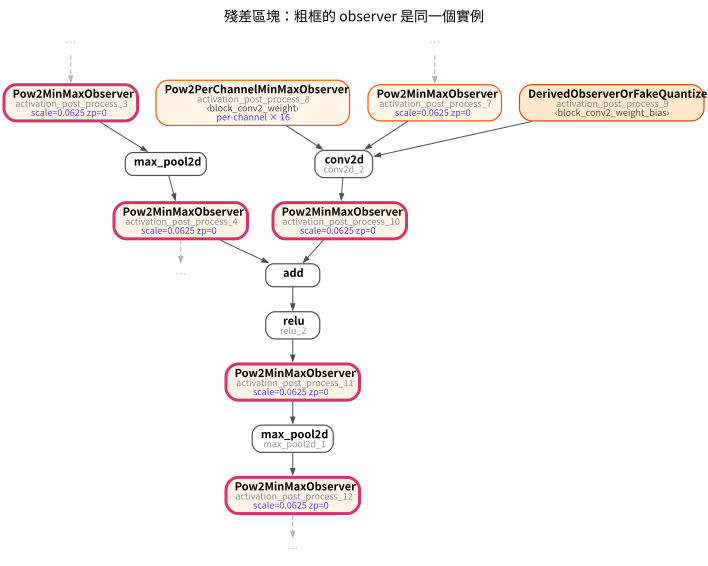

In [8]:
draw(prepared, focus=["max_pool2d", "add", "relu_2", "conv2d_2", "max_pool2d_1"], hops=1,
     highlight=[n.name for n in shared], title="殘差區塊：粗框的 observer 是同一個實例")

約束 (6) 一路連起來：

- `add` 要求兩個輸入（`max_pool2d` 的輸出、`conv2d_2` 的輸出）與輸出同 scale；`add` 後面融合的 `relu_2` 就是它的輸出。
- `max_pool2d` 要求輸入輸出同 scale，所以它的輸入（stem 的 `relu`）也被拉進來；`max_pool2d_1` 同理。

代價是值域較小的 tensor 也只能用這一串裡最大值域決定的 scale。另外，同 scale 不一定是被綁在一起：

In [9]:
s_shared = float(shared_mod.calculate_qparams()[0])
by_chance = [g[1][0].args[0].name for g in groups.values()
             if g[0] is not shared_mod and float(g[0].calculate_qparams()[0]) == s_shared]
print(f"被綁在一起的 scale：2^{torch.log2(torch.tensor(s_shared)):.0f}；其他 scale 剛好相同的 tensor：{by_chance}")

被綁在一起的 scale：2^-4；其他 scale 剛好相同的 tensor：['relu_1', 'relu_3']


這些 tensor 的 scale 和那一串相同，但它們有自己的 observer：2 的冪次很粗，剛好落在同一格。換一份校準資料，它們可能就不同；被綁在一起的那一串則永遠相同。

圖上沒有 `batch_norm`：`prepare_pt2e` 先把 BN 折進 conv（M04-1）。`adaptive_avg_pool2d` 不在 `VPU_OPS`，沒有標籤，留在 fp32（M10-3 看它怎麼把圖切開）。

## E. `convert_pt2e` 之後的 Q/DQ 圖

In [10]:
converted = convert_pt2e(prepared)
q = [n for n in qdq_nodes(converted) if n.target == torch.ops.quantized_decomposed.quantize_per_tensor.default]
scales = torch.tensor([float(n.args[1]) for n in q])
pow2 = bool(torch.all(torch.log2(scales) == torch.round(torch.log2(scales))))
zp0 = all(n.args[2] == 0 for n in q)
print(f"quantize_per_tensor {len(q)} 個：scale 全是 2 的冪次 {pow2}；zero point 全是 0 {zp0}")
assert pow2 and zp0

quantize_per_tensor 11 個：scale 全是 2 的冪次 True；zero point 全是 0 True


最後對 fp32 輸出算一次 SQNR，只確認模型仍正常運作（沒有拆解每條約束各掉多少精度）。對照組是同一份校準資料的 torchao 測試版 XNNPACKQuantizer：

In [11]:
xnn = prepare_pt2e(export_module(model, x, dynamic_batch=False), get_xnnpack_quantizer(is_per_channel=True)[0])
xt = make_tensors(n=BATCH, seed=7)[0]
with torch.no_grad():
    for b in calibration_batches(n=64, batch_size=BATCH):
        xnn(*b)
    xnn = convert_pt2e(xnn)
    y = model(xt)
    s_vpu, s_xnn = sqnr(y, converted(xt)), sqnr(y, xnn(xt))
print(f"對 fp32 輸出的 SQNR：MyVPUQuantizer {s_vpu:.1f} dB；XNNPACKQuantizer（torchao 測試版）{s_xnn:.1f} dB")
assert s_vpu > 15

對 fp32 輸出的 SQNR：MyVPUQuantizer 24.3 dB；XNNPACKQuantizer（torchao 測試版）28.9 dB


## 小結

- 後端 Quantizer = 把硬體約束翻譯成標籤：`qscheme` 管 symmetric，自訂 observer 管 scale 的形式，Shared／Derived 管 scale 之間的關係，「不標」管 op 清單，`validate()` 管標籤表達不了的條件（static shape）。
- 同 scale 的要求會沿著 add、pool 一路連起來；代價由值域較小的 tensor 承擔。
- 這些都是 Quantizer 單方面的承諾。後端編譯器拿到的只有 Q/DQ 圖，要自己檢查（M10-2）、自己切圖（M10-3）。